## qualidade dos dados

In [29]:
import matplotlib.pyplot as plt
import pandas as pd # Adicionado apenas por garantia, pois você usa no código

def nulls_e_zeros(df, title):
    # 1. Identifica os anos únicos disponíveis no dataframe e os ordena
    anos = sorted(df['Período'].dropna().unique())
    num_anos = len(anos)

    # Identifica apenas as colunas de variáveis (excluindo 'Período' e 'Distrito')
    cols_variaveis = [col for col in df.columns if col not in ['Período', 'Distrito']]

    # 2. Cria a figura com subplots (1 linha, múltiplas colunas)
    fig, axes = plt.subplots(nrows=1, ncols=num_anos, figsize=(5 * num_anos, 35), sharey=True)

    # Garante que axes seja iterável caso haja apenas 1 ano na base
    if num_anos == 1:
        axes = [axes]

    # 3. Loop para calcular proporções e plotar cada ano em seu respectivo eixo (ax)
    for ax, ano in zip(axes, anos):
        # Filtra os dados especificamente para o ano do loop
        df_ano = df[df['Período'] == ano]
        
        dados_proporcao = []

        for col in cols_variaveis:
            # Converte os dados para numérico
            s = pd.to_numeric(df_ano[col], errors='coerce')
            total = len(s)

            # Trata caso não haja registros para o ano (evita erro de divisão por zero)
            if total == 0:
                perc_nulos, perc_zeros, perc_maiores_zero = 100, 0, 0
            else:
                perc_nulos = (s.isna().sum() / total) * 100
                perc_zeros = ((s == 0).sum() / total) * 100
                perc_maiores_zero = ((s > 0).sum() / total) * 100

            dados_proporcao.append({
                'Variável': col,
                'Nulos (%)': perc_nulos,
                'Zeros (%)': perc_zeros,
                'Valores > 0 (%)': perc_maiores_zero
            })

        df_prop = pd.DataFrame(dados_proporcao).set_index('Variável')

        # Plotagem das barras no subplot atual (ax)
        df_prop[['Nulos (%)', 'Zeros (%)', 'Valores > 0 (%)']].plot(
            kind='barh',
            stacked=True,
            ax=ax,
            color=['#e74c3c', '#f1c40f', '#2ecc71'],  
            width=0.8,
            legend=False 
        )

        # Ajustes estéticos individuais de cada subplot
        ax.set_title(f'Ano: {int(ano)}', fontsize=25, pad=5)
        ax.set_xlabel('Porcentagem (%)', fontsize=20) # <-- Aumentado o texto do eixo X também para manter proporção
        ax.tick_params(axis='x', labelsize=15)        # <-- Aumentado os números do eixo X
        ax.set_xlim(0, 100)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        
        # Mantém o rótulo do eixo Y apenas no primeiro gráfico
        if ax == axes[0]:
            ax.set_ylabel('Variáveis', fontsize=25)
            # AUMENTANDO O TAMANHO DOS RÓTULOS (nomes das variáveis) DO EIXO Y
            ax.tick_params(axis='y', labelsize=20)    # <-- LINHA ADICIONADA/MODIFICADA
        else:
            ax.set_ylabel('')
            # Oculta os ticks y nos outros gráficos para ficar mais limpo
            ax.tick_params(axis='y', which='both', length=0) 

    # Inverte o eixo Y apenas do primeiro eixo (afeta todos devido ao sharey=True)
    axes[0].invert_yaxis()

    # Adiciona um título geral para a imagem completa
    fig.suptitle('Proporção de Valores Nulos, Zerados e >0 por Variável ao longo dos Anos', fontsize=35, y=1.01)

    # Pega os handles do último gráfico para criar uma legenda única do lado direito
    handles, labels = axes[-1].get_legend_handles_labels()
    
    # AUMENTANDO A FONTE DA LEGENDA E DO TÍTULO DA LEGENDA
    fig.legend(
        handles, 
        labels, 
        title='Categoria', 
        bbox_to_anchor=(1.01, 0.98), 
        loc='upper left', 
        fontsize=25,           # <-- Tamanho da fonte dos itens da legenda
        title_fontsize=30      # <-- Tamanho da fonte do título da legenda ("Categoria")
    )

    plt.tight_layout()

    # 1. Salva a imagem em alta resolução
    plt.savefig(
        f'plots/nullsezeros_{title}.png', 
        dpi=300,                              
        bbox_inches='tight',                
        pad_inches=0.2,                     
        facecolor='white',                  
        transparent=False
    )

    plt.show()

In [31]:
import pandas as pd
df1sel = pd.read_csv("raw/merged_1sel_full.csv", delimiter=';')
df1sel = df1sel[(df1sel['Período']>=2016) & (df1sel['Período'] < 2026)]
df1sel = df1sel.drop(columns=['Unnamed: 0'])

df3sel = pd.read_csv("normalizado/sel3_full.csv", delimiter=';')
df3sel = df3sel[(df3sel['Período']>=2016) & (df3sel['Período'] < 2026)]
df3sel = df3sel.drop(columns=['Unnamed: 0'])

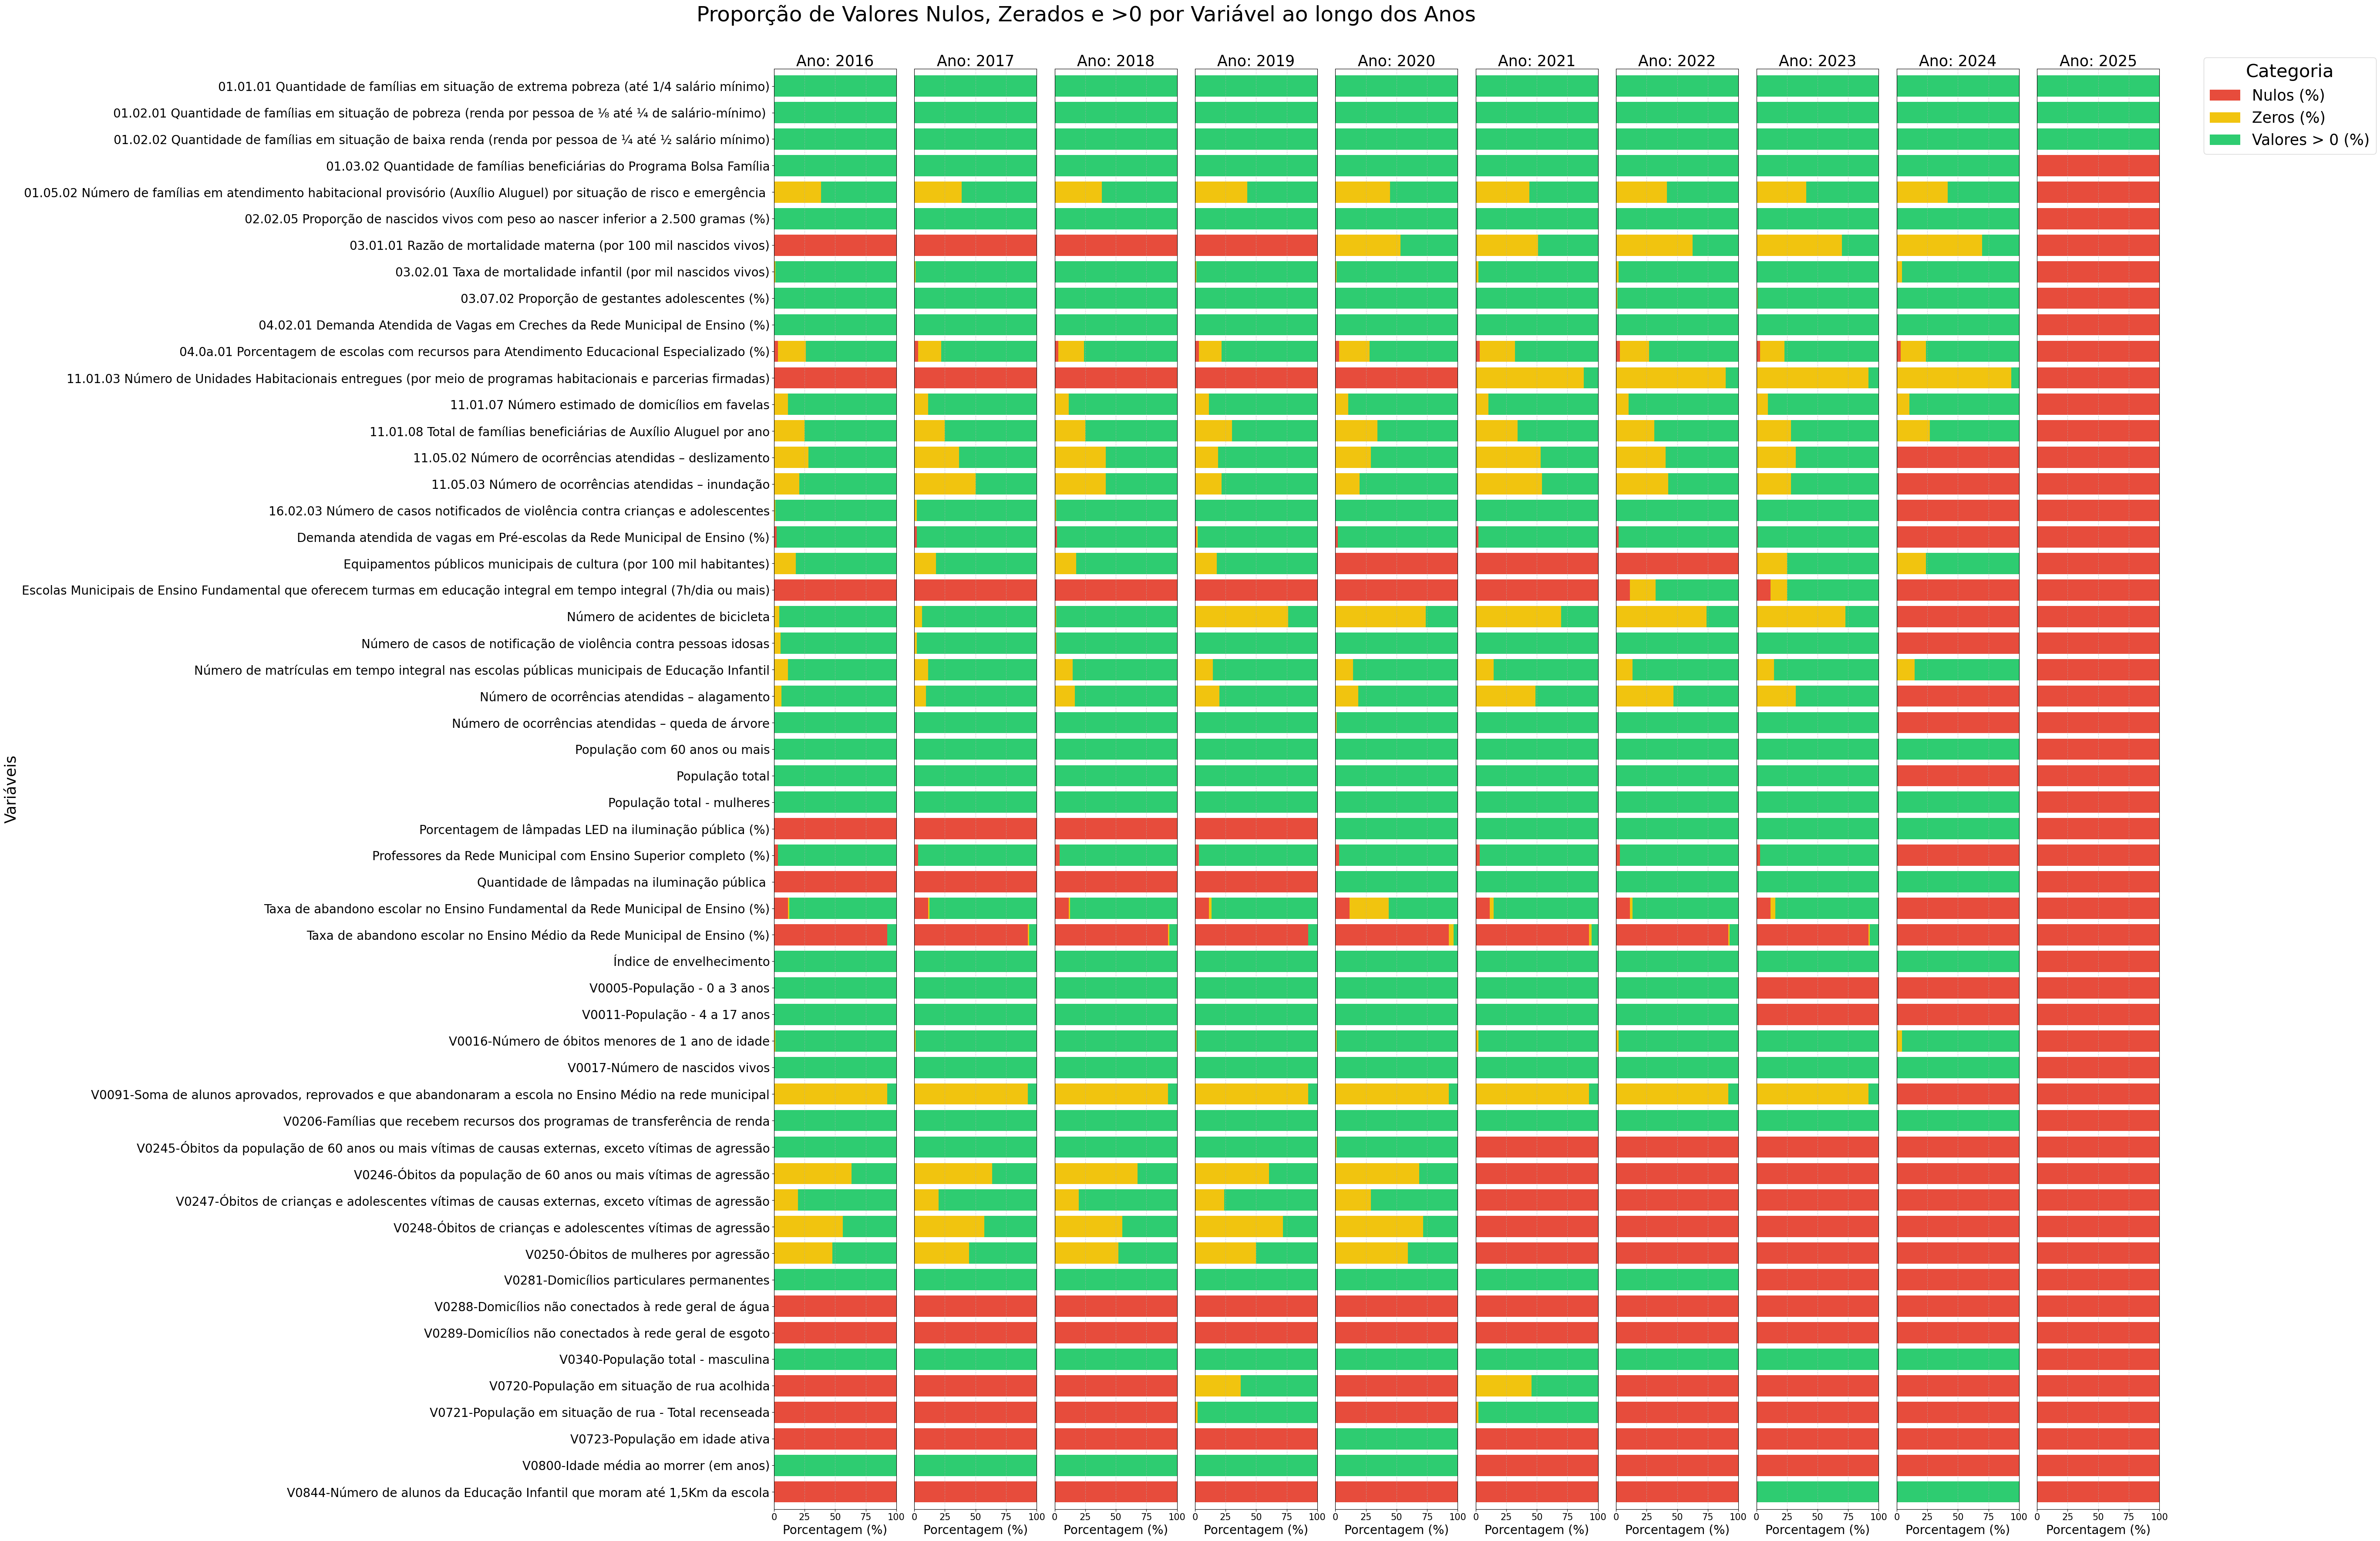

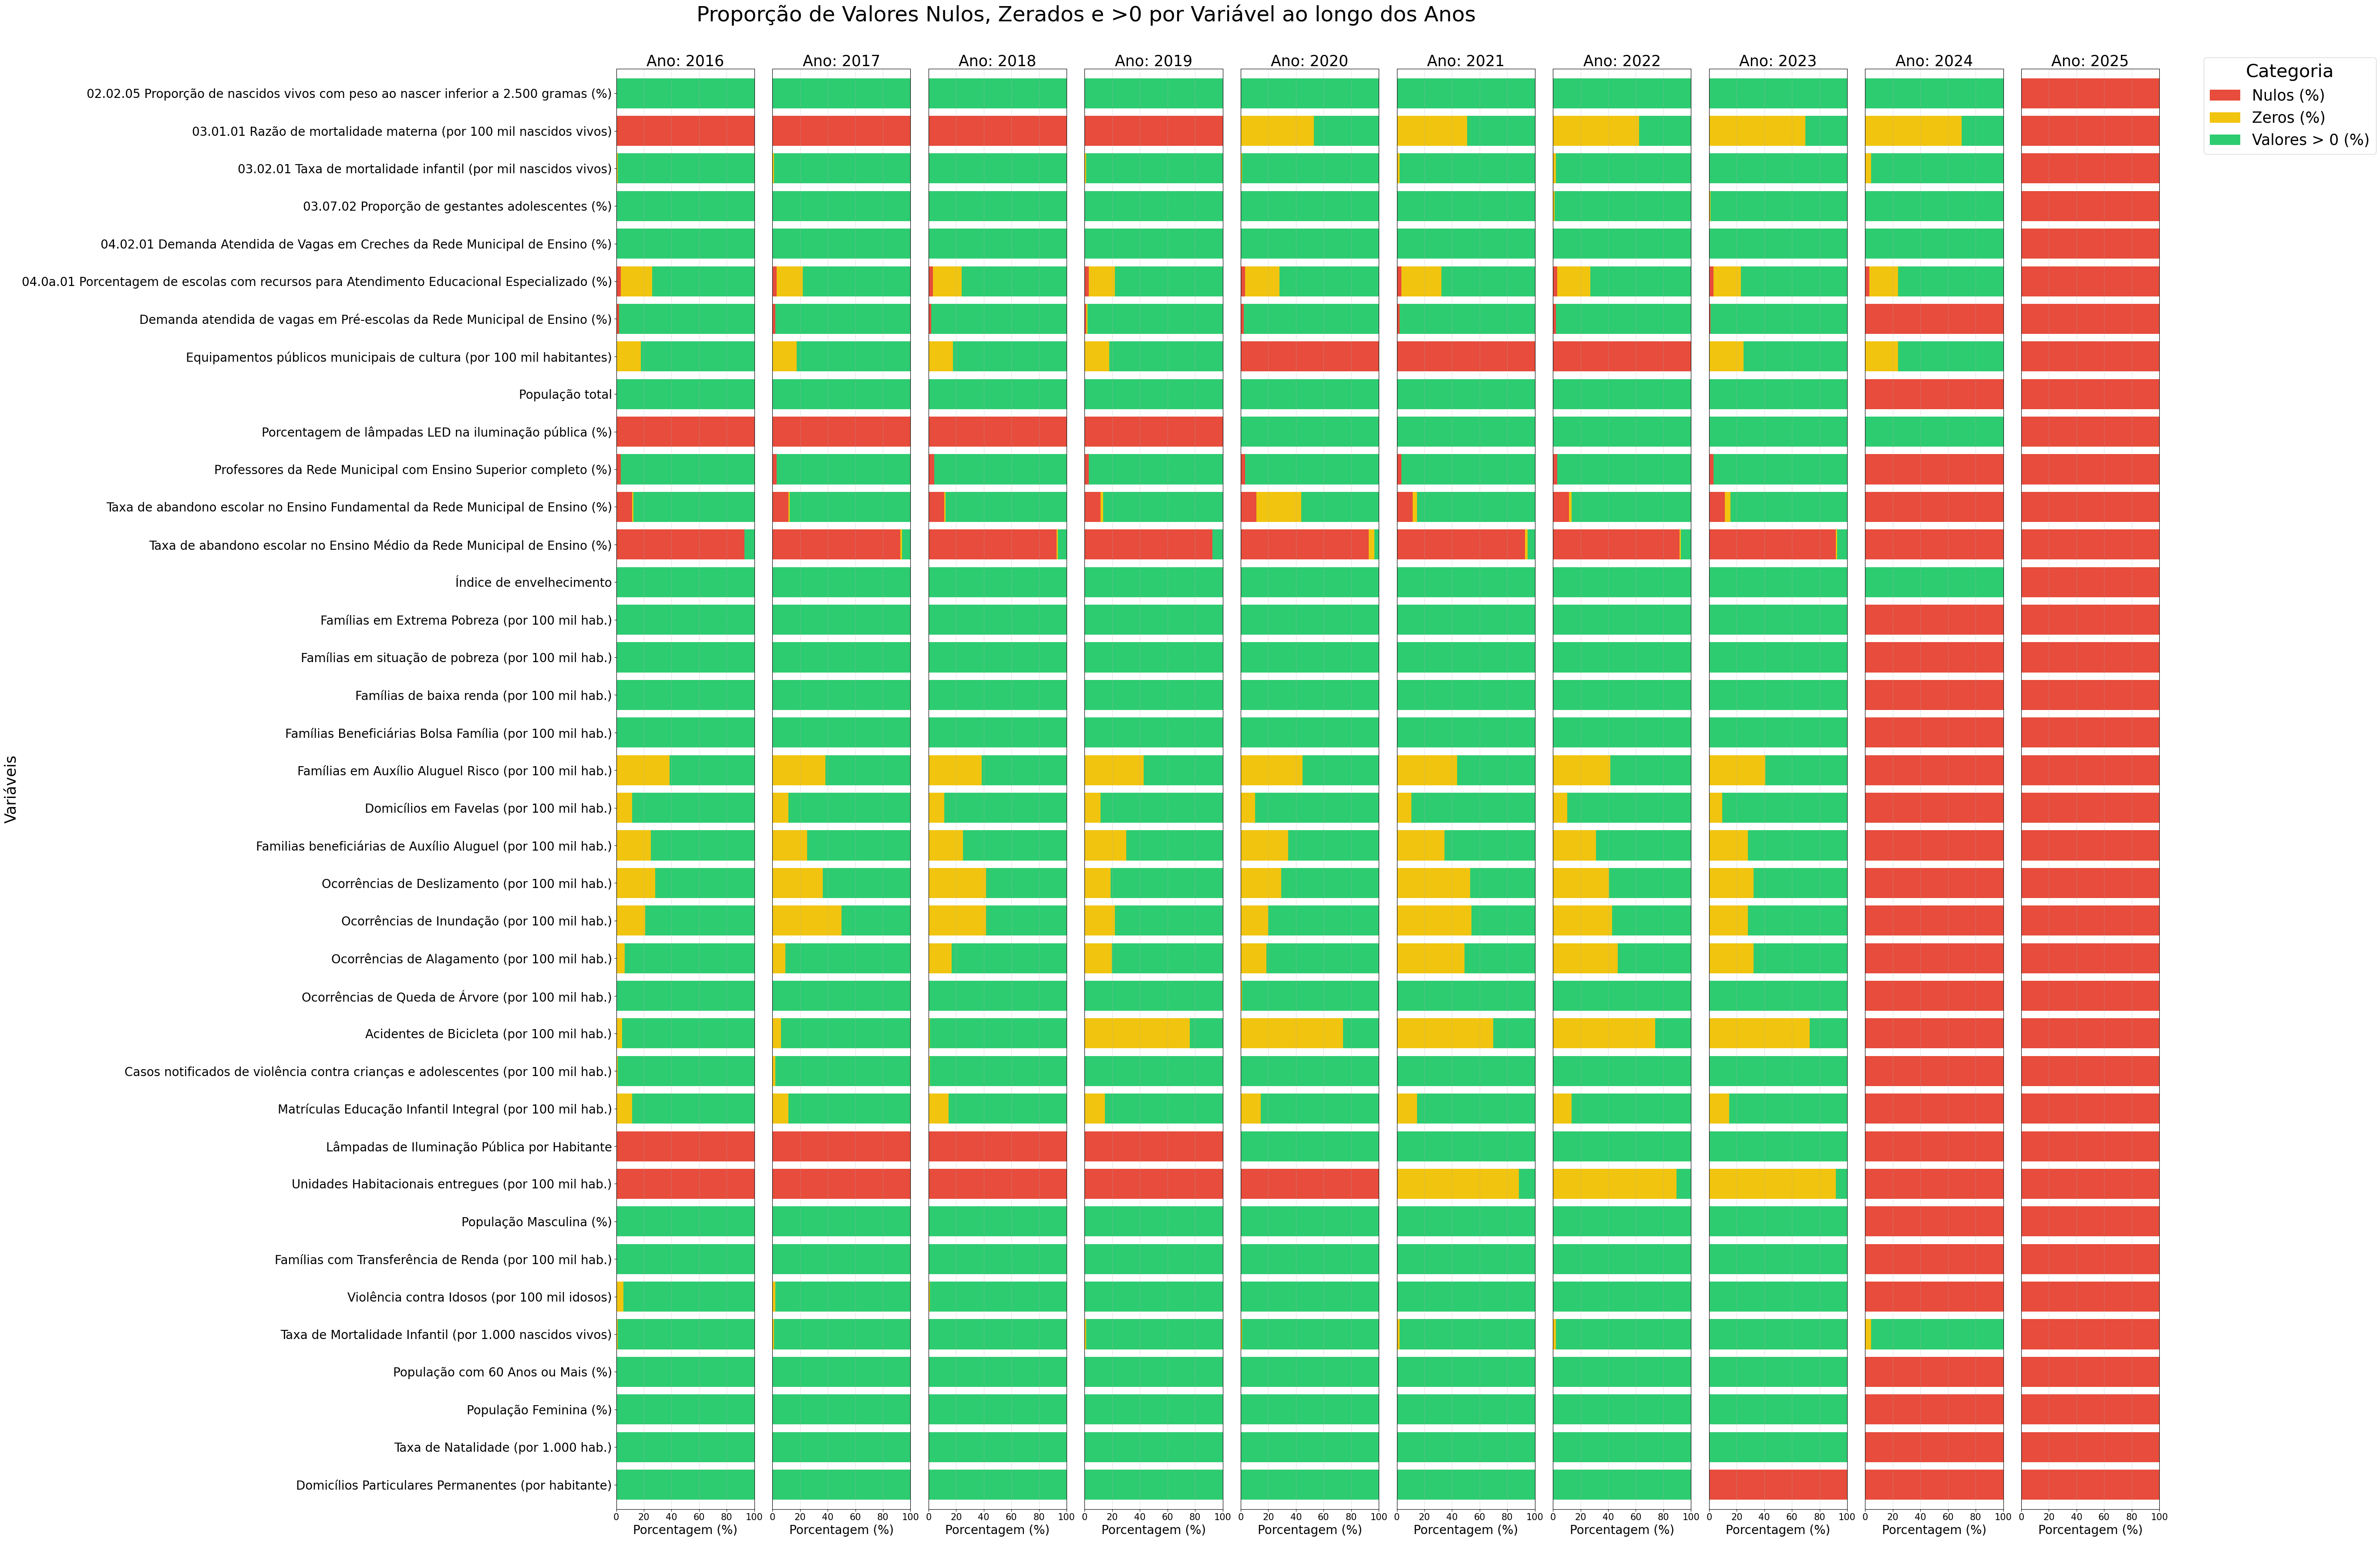

In [32]:
nulls_e_zeros(df1sel, 'df1sel')
nulls_e_zeros(df3sel, 'df3sel')

## correlação

In [ ]:
import pandas as pd
df = pd.read_csv("raw/merged_2sel_full.csv", delimiter=';')
#df = df[df['Período']>=2016]
df = df.drop(columns=['Unnamed: 0'])

KeyError: 'Período'